# Calibrating an Epidemic Model with Emulators

Run it top to bottom. Every figure is produced here and saved in `images/`.

**Data (real):** the influenza outbreak at a boys' boarding school in the north of England,
January–February 1978 (British Medical Journal, 4 March 1978): daily numbers of boys confined to bed
and convalescent, among 763 boys. Data as distributed in the R package `outbreaks`.

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import time
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
DATA_PATH = os.path.join(PROJECT_ROOT_DIR, "datasets")
os.makedirs(IMAGES_PATH, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## Get the Data

In [3]:
DATA_URL = "https://raw.githubusercontent.com/reconverse/outbreaks/master/data/influenza_england_1978_school.RData"

def load_flu():
    csv = os.path.join(DATA_PATH, "influenza_england_1978_school.csv")
    if not os.path.exists(csv):
        import urllib.request, pyreadr                     # pip install pyreadr (only to convert the file)
        path = os.path.join(DATA_PATH, "influenza_england_1978_school.RData")
        urllib.request.urlretrieve(DATA_URL, path)
        pyreadr.read_r(path)["influenza_england_1978_school"].to_csv(csv, index=False)
    return pd.read_csv(csv, parse_dates=["date"])

flu = load_flu()
N_BOYS = 763
flu["day"] = (flu.date - pd.Timestamp("1978-01-21")).dt.days     # day 0 = 21 January
flu

,date,in_bed,convalescent,day
0,1978-01-22,3,0,1
1,1978-01-23,8,0,2
2,1978-01-24,26,0,3
3,1978-01-25,76,0,4
4,1978-01-26,225,9,5
5,1978-01-27,298,17,6
6,1978-01-28,258,105,7
7,1978-01-29,233,162,8
8,1978-01-30,189,176,9
9,1978-01-31,128,166,10


Saving figure outbreak_data_plot


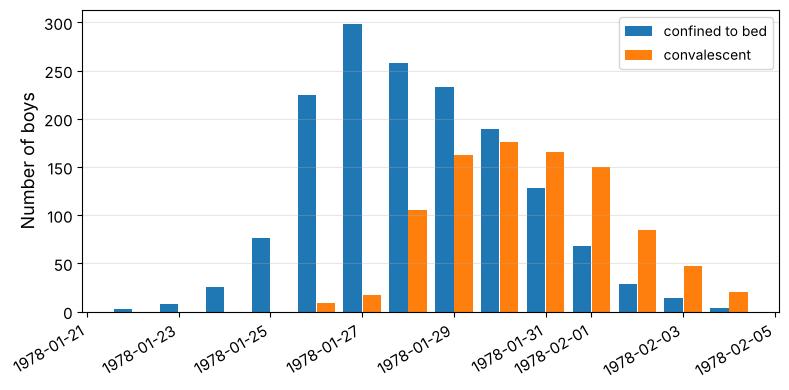

peak: 298 boys in bed (39% of the school) on 27 January


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(flu.date - pd.Timedelta(hours=5), flu.in_bed, width=0.4, label="confined to bed")
ax.bar(flu.date + pd.Timedelta(hours=5), flu.convalescent, width=0.4, label="convalescent")
ax.set_ylabel("Number of boys")
ax.legend()
fig.autofmt_xdate()
ax.grid(True, axis="y", alpha=0.3)
save_fig("outbreak_data_plot")
plt.show()
print(f"peak: {flu.in_bed.max()} boys in bed ({100 * flu.in_bed.max() / N_BOYS:.0f}% of the school) on {flu.date[flu.in_bed.idxmax()]:%d %B}")

## The Simulator

In [5]:
DT = 0.1                                    # days per step
DAYS = flu.day.values                       # observation days 1 ... 14

def simulate(theta, n_rep=1, seed=None, return_paths=False, contact_cut=None):
    """Stochastic S-E-I-C-R model (binomial chain, tau = 0.1 day), vectorized over parameter sets and replicates.
    theta: array (n, 4) of [beta, latent period, days in bed, days convalescent].
    E: infected, not yet ill; I: ill and confined to bed (infectious); C: convalescent; R: back in class.
    Returns the in-bed and convalescent counts at 8 a.m. of each observation day: shape (n, n_rep, 2, 14)."""
    rng = np.random.default_rng(seed)
    theta = np.atleast_2d(theta)
    beta = np.repeat(theta[:, 0], n_rep)
    p_EI = 1 - np.exp(-DT / np.repeat(theta[:, 1], n_rep))
    p_IC = 1 - np.exp(-DT / np.repeat(theta[:, 2], n_rep))
    p_CR = 1 - np.exp(-DT / np.repeat(theta[:, 3], n_rep))
    n = len(beta)
    S = np.full(n, N_BOYS - 1); E = np.zeros(n, int); I = np.ones(n, int); C = np.zeros(n, int)
    out = np.zeros((n, 2, len(DAYS)))
    paths = []
    steps = int(round(DAYS.max() / DT))
    obs_steps = {int(round(d / DT)): k for k, d in enumerate(DAYS)}
    for step in range(1, steps + 1):
        b = beta if contact_cut is None or step * DT < contact_cut[0] else beta * (1 - contact_cut[1])
        new_E = rng.binomial(S, 1 - np.exp(-b * I / N_BOYS * DT))
        new_I = rng.binomial(E, p_EI)
        new_C = rng.binomial(I, p_IC)
        new_R = rng.binomial(C, p_CR)
        S -= new_E; E += new_E - new_I; I += new_I - new_C; C += new_C - new_R
        if step in obs_steps:
            out[:, 0, obs_steps[step]], out[:, 1, obs_steps[step]] = I, C
        if return_paths:
            paths.append(I.copy())
    out = out.reshape(len(theta), n_rep, 2, len(DAYS))
    return (out, np.array(paths), N_BOYS - S) if return_paths else out

theta_demo = np.array([[1.8, 1.0, 2.0, 2.5]])
t0 = time.time()
demo = simulate(theta_demo, n_rep=20, seed=1)
print(f"20 runs in {1e3 * (time.time() - t0):.0f} ms; boys in bed on day 6: {demo[0, :, 0, 5].astype(int)}")

20 runs in 20 ms; boys in bed on day 6: [37 44 54  9  0 21 13 12 34  0  0  8  0  0  3 15  0 19 12 26]


Saving figure simulator_runs_plot


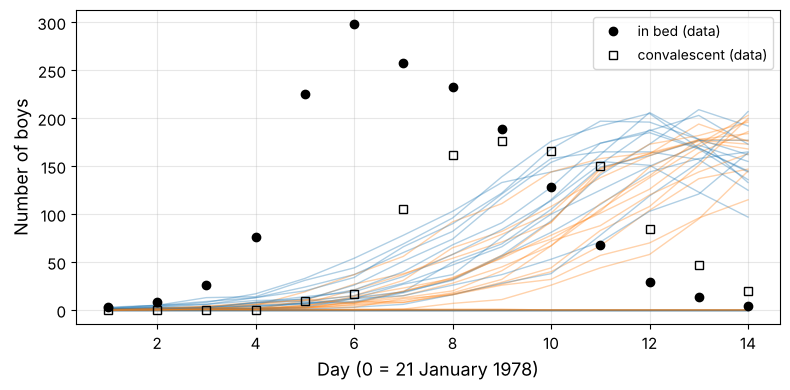

runs that fizzled out (fewer than 10 boys ever in bed): 6 of 20


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
for r in range(20):
    ax.plot(DAYS, demo[0, r, 0], color="C0", alpha=0.35, lw=1)
    ax.plot(DAYS, demo[0, r, 1], color="C1", alpha=0.35, lw=1)
ax.plot(DAYS, flu.in_bed, "ko", label="in bed (data)")
ax.plot(DAYS, flu.convalescent, "ks", mfc="none", label="convalescent (data)")
ax.set_xlabel("Day (0 = 21 January 1978)"); ax.set_ylabel("Number of boys")
ax.legend()
ax.grid(True, alpha=0.3)
save_fig("simulator_runs_plot")
plt.show()
print("runs that fizzled out (fewer than 10 boys ever in bed):", int((demo[0, :, 0].max(axis=1) < 10).sum()), "of 20")

## Summaries, Prior and the Cost Model

In [7]:
# We emulate square roots of counts (variance-stabilizing for counts) at a few informative days.
SUM_DAYS_BED = [3, 4, 5, 7, 9, 11]
SUM_DAYS_CONV = [7, 9, 11, 13]
SUMMARIES = [f"bed_day{d}" for d in SUM_DAYS_BED] + [f"conv_day{d}" for d in SUM_DAYS_CONV]

def summarize(out):
    """out: (..., 2, 14) counts -> (..., 10) square-root summaries."""
    ib = [list(DAYS).index(d) for d in SUM_DAYS_BED]
    ic = [list(DAYS).index(d) for d in SUM_DAYS_CONV]
    return np.sqrt(np.concatenate([out[..., 0, ib], out[..., 1, ic]], axis=-1))

z_obs = summarize(np.stack([flu.in_bed.values, flu.convalescent.values])[None])[0]
OBS_VAR = 0.25 + (0.1 * z_obs) ** 2           # Poisson-like counting error (sqrt scale) + 10% reporting error
PARAMS = ["beta", "latent_days", "bed_days", "convalescent_days"]
LOW = np.array([0.5, 0.05, 1.0, 1.0])
HIGH = np.array([8.0, 3.0, 5.0, 5.0])
pd.Series(z_obs.round(2), index=SUMMARIES)

bed_day3       5.10
bed_day4       8.72
bed_day5      15.00
bed_day7      16.06
bed_day9      13.75
bed_day11      8.25
conv_day7     10.25
conv_day9     13.27
conv_day11    12.25
conv_day13     6.86
dtype: float64

## Wave 1 of History Matching

In [8]:
from scipy.stats import qmc

N_PER_WAVE, N_REP = 120, 8
def run_wave(X, seed):
    """Runs the simulator N_REP times at each design point; returns summary means and variances.
    Runs that fizzle out early are discarded (we know an outbreak happened)."""
    out = simulate(X, n_rep=N_REP, seed=seed)
    took_off = out[:, :, 0, :].max(axis=2) >= 10
    s = summarize(out)
    mean = np.array([s[i][took_off[i]].mean(0) if took_off[i].sum() >= 2 else np.full(len(SUMMARIES), np.nan) for i in range(len(X))])
    var = np.array([s[i][took_off[i]].var(0, ddof=1) if took_off[i].sum() >= 2 else np.full(len(SUMMARIES), np.nan) for i in range(len(X))])
    return mean, var, took_off.sum(1)

X1 = qmc.scale(qmc.LatinHypercube(d=4, optimization="random-cd", seed=1).random(N_PER_WAVE), LOW, HIGH)
t0 = time.time()
m1, v1, n1 = run_wave(X1, seed=11)
total_runs = N_PER_WAVE * N_REP
print(f"wave 1: {total_runs} simulator runs in {time.time() - t0:.1f} s; design points where the epidemic took off: "
      f"{np.mean(np.isfinite(m1[:, 0])):.0%}")

wave 1: 960 simulator runs in 0.0 s; design points where the epidemic took off: 98%


In [9]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C, WhiteKernel

class Emulator:
    """One GP per summary, on inputs scaled to [0, 1]. The noise of each design point is known:
    the variance of the mean of its replicates. A second GP emulates the (log) stochastic variance."""
    def __init__(self, low, high):
        self.low, self.high = low, high
    def _s(self, X):
        return (X - self.low) / (self.high - self.low)
    def fit(self, X, mean, var, nrep):
        ok = np.all(np.isfinite(mean), axis=1)
        X, mean, var, nrep = self._s(X[ok]), mean[ok], var[ok], nrep[ok]
        self.gps, self.vgps = [], []
        for k in range(mean.shape[1]):
            kern = C(1.0) * Matern(np.ones(4), (1e-2, 1e2), nu=2.5)
            gp = GaussianProcessRegressor(kern, alpha=var[:, k] / nrep + 1e-6, normalize_y=True,
                                          n_restarts_optimizer=2, random_state=0).fit(X, mean[:, k])
            self.gps.append(gp)
            vk = C(1.0) * Matern(np.ones(4), (1e-2, 1e2), nu=2.5) + WhiteKernel(0.1)
            self.vgps.append(GaussianProcessRegressor(vk, normalize_y=True, random_state=0).fit(X, np.log(var[:, k] + 1e-3)))
        return self
    def predict(self, X):
        Xs = self._s(np.atleast_2d(X))
        mu, sd = zip(*[gp.predict(Xs, return_std=True) for gp in self.gps])
        stoch = np.exp(np.column_stack([v.predict(Xs) for v in self.vgps]))
        return np.column_stack(mu), np.column_stack(sd) ** 2, stoch

t0 = time.time()
em1 = Emulator(LOW, HIGH).fit(X1, m1, v1, n1)
print(f"10 + 10 GPs fitted in {time.time() - t0:.0f} s")

10 + 10 GPs fitted in 16 s


In [10]:
# Leave-one-out style check on fresh points: run 30 new design points and compare
Xv = qmc.scale(qmc.LatinHypercube(d=4, seed=99).random(30), LOW, HIGH)
mv, vv, nv = run_wave(Xv, seed=99)
mu_v, var_v, st_v = em1.predict(Xv)
ok = np.all(np.isfinite(mv), axis=1)
std_err = (mv[ok] - mu_v[ok]) / np.sqrt(var_v[ok] + vv[ok] / nv[ok, None])
print(f"standardized errors on 30 new points: mean {std_err.mean():.2f}, std {std_err.std():.2f}, "
      f"fraction within ±2: {np.mean(np.abs(std_err) < 2):.0%}")

standardized errors on 30 new points: mean -0.30, std 1.13, fraction within ±2: 91%


In [11]:
def implausibility(em, X):
    mu, em_var, stoch = em.predict(X)
    I = np.abs(z_obs - mu) / np.sqrt(em_var + stoch + OBS_VAR)
    return np.sort(I, axis=1)[:, -2]                 # second-largest: robust to one poorly emulated summary

CUTOFF = 3.0
rng = np.random.default_rng(0)
cand = LOW + rng.random((200_000, 4)) * (HIGH - LOW)
t0 = time.time()
I1 = implausibility(em1, cand)
nroy1 = cand[I1 < CUTOFF]
print(f"implausibility of 200,000 candidates in {time.time() - t0:.0f} s; "
      f"non-implausible fraction after wave 1: {len(nroy1) / len(cand):.2%}")

implausibility of 200,000 candidates in 32 s; non-implausible fraction after wave 1: 26.17%


## More Waves

In [12]:
waves = [dict(X=X1, nroy_frac=len(nroy1) / len(cand), nroy=nroy1, em=em1)]
emulators, X_all, m_all, v_all, n_all = [em1], X1, m1, v1, n1
nroy = nroy1
for w in (2, 3):
    Xw = nroy[np.random.default_rng(w).choice(len(nroy), N_PER_WAVE, replace=False)]
    mw, vw, nw = run_wave(Xw, seed=10 + w)
    total_runs += N_PER_WAVE * N_REP
    X_all, m_all, v_all, n_all = np.vstack([X_all, Xw]), np.vstack([m_all, mw]), np.vstack([v_all, vw]), np.r_[n_all, nw]
    lo, hi = nroy.min(0), nroy.max(0)
    em_w = Emulator(lo, hi).fit(Xw, mw, vw, nw)       # each wave's emulator focuses on the current region
    emulators.append(em_w)
    keep = np.ones(len(cand), bool)
    for em_ in emulators:                              # a point must pass ALL waves' emulators
        keep &= implausibility(em_, cand) < CUTOFF
    nroy = cand[keep]
    waves.append(dict(X=Xw, nroy_frac=keep.mean(), nroy=nroy, em=em_w))
    print(f"wave {w}: non-implausible fraction {keep.mean():.3%} ({keep.sum():,} candidates), total runs so far {total_runs:,}")

wave 2: non-implausible fraction 20.445% (40,890 candidates), total runs so far 1,920


wave 3: non-implausible fraction 18.250% (36,501 candidates), total runs so far 2,880


Saving figure history_matching_plot


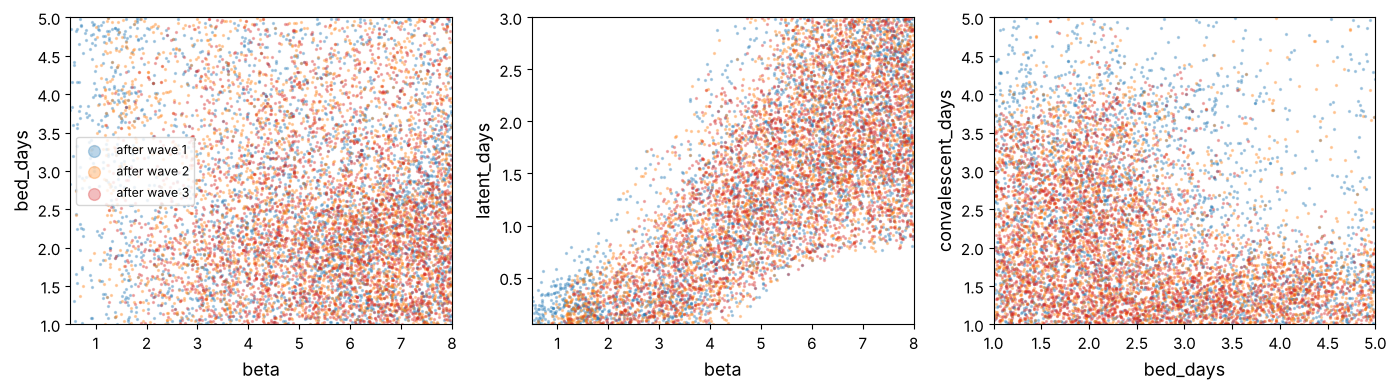

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pairs = [(0, 2), (0, 1), (2, 3)]
for ax, (i, j) in zip(axes, pairs):
    for w, (wave, col) in enumerate(zip(waves, ("C0", "C1", "C3"))):
        sub = wave["nroy"][np.random.default_rng(w).choice(len(wave["nroy"]), min(3000, len(wave["nroy"])), replace=False)]
        ax.scatter(sub[:, i], sub[:, j], s=2, color=col, alpha=0.3, label=f"after wave {w + 1}")
    ax.set_xlim(LOW[i], HIGH[i]); ax.set_ylim(LOW[j], HIGH[j])
    ax.set_xlabel(PARAMS[i]); ax.set_ylabel(PARAMS[j])
axes[0].legend(markerscale=6, fontsize=9)
save_fig("history_matching_plot")
plt.show()

## From Non-Implausible to Posterior

In [14]:
# Importance sampling over the final non-implausible region with a Gaussian synthetic likelihood
# built from the last emulator (uniform prior over the original box).
em_last = emulators[-1]
mu, em_var, stoch = em_last.predict(nroy)
tot = em_var + stoch + OBS_VAR
loglik = -0.5 * np.sum((z_obs - mu) ** 2 / tot + np.log(tot), axis=1)
w = np.exp(loglik - loglik.max()); w /= w.sum()
post = nroy[np.random.default_rng(1).choice(len(nroy), 4000, p=w)]
post_df = pd.DataFrame(post, columns=PARAMS)
post_df["R0"] = post_df.beta * post_df.bed_days
print(f"effective sample size: {1 / np.sum(w ** 2):.0f}")
post_df.describe(percentiles=[0.05, 0.5, 0.95]).T[["5%", "50%", "95%"]].round(2)

effective sample size: 2107


,5%,50%,95%
beta,2.47,5.74,7.81
latent_days,0.23,1.33,2.05
bed_days,1.48,2.12,2.70
convalescent_days,1.13,1.52,1.95
R0,4.71,11.79,18.11


In [15]:
# Ground truth for comparison: brute-force ABC with the simulator itself (no emulator)
t0 = time.time()
N_ABC = 100_000
Xa = LOW + np.random.default_rng(5).random((N_ABC, 4)) * (HIGH - LOW)
sa = summarize(np.concatenate([simulate(Xa[i:i + 10_000], seed=i)[:, 0] for i in range(0, N_ABC, 10_000)]))
dist = np.sqrt(np.sum((sa - z_obs) ** 2 / OBS_VAR, axis=1))
acc = Xa[dist <= np.quantile(dist, 0.005)]
abc_df = pd.DataFrame(acc, columns=PARAMS)
abc_df["R0"] = abc_df.beta * abc_df.bed_days
print(f"ABC: {N_ABC:,} simulator runs in {time.time() - t0:.0f} s, {len(acc)} accepted (0.5%)")
cmp = pd.DataFrame({"emulator: median": post_df.median(), "emulator: 90% interval": post_df.quantile(0.05).round(2).astype(str) + "–" + post_df.quantile(0.95).round(2).astype(str),
                    "ABC: median": abc_df.median(), "ABC: 90% interval": abc_df.quantile(0.05).round(2).astype(str) + "–" + abc_df.quantile(0.95).round(2).astype(str)})
print(f"simulator runs: emulator approach {total_runs:,}, brute-force ABC {N_ABC:,}")
cmp.round(2)

ABC: 100,000 simulator runs in 5 s, 500 accepted (0.5%)
simulator runs: emulator approach 2,880, brute-force ABC 100,000


,emulator: median,emulator: 90% interval,ABC: median,ABC: 90% interval
beta,5.74,2.47–7.81,5.96,2.59–7.78
latent_days,1.33,0.23–2.05,1.54,0.49–2.52
bed_days,2.12,1.48–2.7,2.09,1.59–2.66
convalescent_days,1.52,1.13–1.95,1.50,1.1–1.92
R0,11.79,4.71–18.11,11.87,5.58–17.84


Saving figure posterior_plot


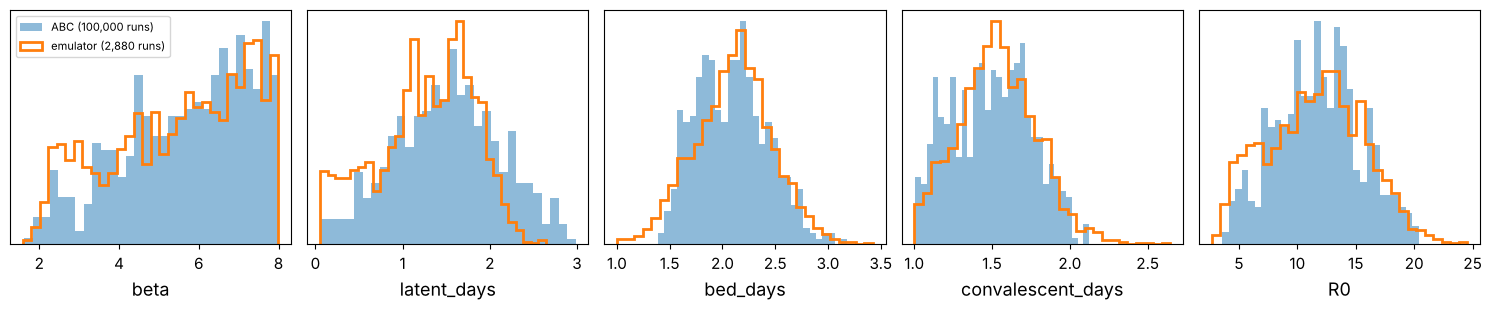

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, p in zip(axes, PARAMS + ["R0"]):
    ax.hist(abc_df[p], bins=30, density=True, alpha=0.5, label="ABC (100,000 runs)")
    ax.hist(post_df[p], bins=30, density=True, histtype="step", lw=2, label=f"emulator ({total_runs:,} runs)")
    ax.set_xlabel(p); ax.set_yticks([])
axes[0].legend(fontsize=8)
save_fig("posterior_plot")
plt.show()

Saving figure posterior_predictive_plot


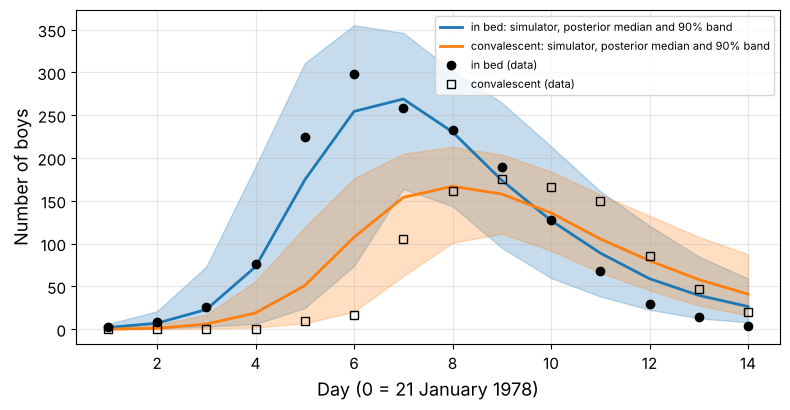

data points inside the 90% posterior predictive band: 86%
boys ever ill in the calibrated model: median 763, 90% interval 758-763; reported in the BMJ: 512


In [17]:
pp = simulate(post[:300], n_rep=1, seed=3)[:, 0]
took = pp[:, 0].max(1) >= 10
pp = pp[took]
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (col, name) in enumerate((("C0", "in bed"), ("C1", "convalescent"))):
    lo_, med_, hi_ = np.percentile(pp[:, k], [5, 50, 95], axis=0)
    ax.fill_between(DAYS, lo_, hi_, color=col, alpha=0.25)
    ax.plot(DAYS, med_, color=col, lw=2, label=f"{name}: simulator, posterior median and 90% band")
ax.plot(DAYS, flu.in_bed, "ko", label="in bed (data)")
ax.plot(DAYS, flu.convalescent, "ks", mfc="none", label="convalescent (data)")
ax.set_xlabel("Day (0 = 21 January 1978)"); ax.set_ylabel("Number of boys")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
save_fig("posterior_predictive_plot")
plt.show()
inside = np.mean([(np.percentile(pp[:, k], 5, axis=0) <= obs) & (obs <= np.percentile(pp[:, k], 95, axis=0))
                  for k, obs in enumerate((flu.in_bed.values, flu.convalescent.values))])
print(f"data points inside the 90% posterior predictive band: {inside:.0%}")
_, paths_pp, ever_pp = simulate(post[:1000], n_rep=1, seed=4, return_paths=True)
ever_pp = ever_pp[paths_pp.max(0) >= 10]              # outbreaks that took off
print(f"boys ever ill in the calibrated model: median {np.median(ever_pp):.0f}, 90% interval "
      f"{np.percentile(ever_pp, 5):.0f}-{np.percentile(ever_pp, 95):.0f}; reported in the BMJ: 512")

## Use the Calibrated Model: What If the School Had Acted Earlier?

In [18]:
rows = []
for cut_day, cut in ((None, 0.0), (3, 0.5), (5, 0.5), (3, 0.8), (5, 0.8)):
    out, paths, ever = simulate(post[:1000], n_rep=1, seed=7, return_paths=True,
                                contact_cut=None if cut_day is None else (cut_day, cut))
    rows.append({"scenario": "no intervention" if cut_day is None else f"contacts -{int(100 * cut)}% from day {cut_day}",
                 "peak in bed (median)": np.median(paths.max(0)), "peak in bed (90th pct)": np.percentile(paths.max(0), 90),
                 "boys ever ill (median)": np.median(ever), "boys ever ill (90th pct)": np.percentile(ever, 90)})
inter = pd.DataFrame(rows).set_index("scenario")
inter.round(0)

,peak in bed (median),peak in bed (90th pct),boys ever ill (median),boys ever ill (90th pct)
scenario,,,,
no intervention,295.0,361.0,763.0,763.0
contacts -50% from day 3,234.0,292.0,759.0,763.0
contacts -50% from day 5,264.0,333.0,761.0,763.0
contacts -80% from day 3,117.0,186.0,560.0,718.0
contacts -80% from day 5,235.0,323.0,720.0,759.0


## Launch

In [19]:
import json
os.makedirs("animations", exist_ok=True)
anim = dict(
    N=N_BOYS, days=DAYS.tolist(), in_bed=flu.in_bed.tolist(), conv=flu.convalescent.tolist(),
    low=LOW.tolist(), high=HIGH.tolist(), params=PARAMS,
    waves=[np.round(wv["nroy"][np.random.default_rng(i).choice(len(wv["nroy"]), min(1500, len(wv["nroy"])), replace=False)], 3).tolist()
           for i, wv in enumerate(waves)],
    design=[np.round(wv["X"], 3).tolist() for wv in waves], nroy_frac=[float(wv["nroy_frac"]) for wv in waves],
    post=np.round(post[:800], 3).tolist(), abc=np.round(acc[:500], 3).tolist(), runs=int(total_runs))
with open(os.path.join("animations", "data.json"), "w") as f:
    json.dump(anim, f, separators=(",", ":"))
print("exported", os.path.getsize(os.path.join("animations", "data.json")) // 1024, "KB")

exported 154 KB
